In [1]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import st_gears


In [2]:
import scanpy as sc 

import pandas as pd
refAD = sc.read_h5ad("rep2_spot.h5ad")
queryAD = sc.read_h5ad("rep1_spot.h5ad")
refDF = pd.read_csv("valis_output/ref_cell_positions.csv")
queryDF = pd.read_csv("valis_output/moving_valisOutput.csv")
refDF.index = refDF.Cell_Num.astype(str)
queryDF.index = queryDF.Cell_Num.astype(str)
print(refAD.obs.shape, queryAD.obs.shape, refDF.shape, queryDF.shape)
refAD.obs['New_X'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_X']
refAD.obs['New_Y'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_Y']

queryAD.obs['New_X'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_X']
queryAD.obs['New_Y'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_Y']
sc.pp.normalize_total(refAD, target_sum=1e2)
sc.pp.normalize_total(queryAD, target_sum=1e2)
sc.pp.log1p(refAD)
sc.pp.log1p(queryAD)

sc.pp.scale(refAD)
sc.pp.scale(queryAD)

(3801, 12) (3184, 12) (3801, 7) (3184, 10)


In [3]:
refAD.obsm['spatial'] = np.column_stack([refAD.obs[['New_X', 'New_Y']].values, np.ones(refAD.shape[0])])
queryAD.obsm['spatial'] = np.column_stack([queryAD.obs[['New_X', 'New_Y']].values, np.zeros(queryAD.shape[0])])


In [4]:
cols = [
    'Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage'
]
# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')

In [5]:
slicesl = [queryAD, refAD]

In [6]:
import os
import st_gears
import warnings

warnings.filterwarnings('ignore')

grp_col = 'CellType'  # name of column in adata.obs that stores grouping information, either cluster or annotation information
binning_on = False  # only turn granularity adjusting on, when you have over 3000 spots in any one of the sections.

# set uniform_weight to False and filter_by_label to True if you trust in your groupping result, and sections are not too far from each other. Otherwise set uniform_weight to True and filter_by_label to False.
uniform_weight = False  # False if using Distributive Constraints, else True
filter_by_label = True  # Filter groups of spot that do not co-occur in two sections when computing anchors

# binning
if binning_on:
    step = 2  # step size for binning. Check your xy coordinates first. For example, when adjacent spots roughly sits 10 away from each other, setting step to 20 would decrease spots for 4 times in binning result. Remain roughly at least 200 spots in each section after binning.
    slice_srk_li = [st_gears.binning(slice_, grp_col, step) for slice_ in slicesl]  # 'slice_srk_li' means 'shrinked slice list'
else:
    slice_srk_li = slicesl

# Compute anchors
anncell_cid = st_gears.helper.gen_anncell_cid_from_all(slice_srk_li, grp_col)
pili, tyscoreli, alphali, regis_ilist, ali, bli = st_gears.serial_align(slice_srk_li, anncell_cid, label_col=grp_col, start_i=0, end_i=len(slicesl)-1,  # index of start and end section from slicesl to be aligned
tune_alpha_li=[0.8, 0.2, 0.05, 0.013],  # regularization factor list, recommend to fill values exponentially change among 0 and 1. Longer list indicates finer tuning resolution
numItermax=200,  # max number of iteration during optimization
dissimilarity_val='kl', dissimilarity_weight_val='kl',
    uniform_weight=uniform_weight, map_method_dis2wei='logistic',
    filter_by_label=filter_by_label,
    use_gpu=True, verbose=True)  # show each iteration or not


# Rigid registration
fil_pc = 20  # not recommended to change # fil_pc_rigid / 100 * (maximum_probability - minimum_probability) + minimum_probability is set as theshhold to filter anchors
slice_srk_li = st_gears.stack_slices_pairwise_rigid([slice_srk_li[i] for i in regis_ilist], pili,label_col=grp_col,fil_pc=fil_pc,  filter_by_label=filter_by_label)


# elastic registration
if binning_on:
    pixel_size = step  # pixel step size of elastic field. 
else:
    pixel_size = 1  # if not binned, input rough distance between adjacent spots on each section. 
sigma = 1  # not recommended to change. kernel size of Gaussian Filters, with a higher value indicating a smoother elastic field
slice_srk_li = st_gears.stack_slices_pairwise_elas_field([slice_srk_li[i] for i in regis_ilist], pili,label_col=grp_col,pixel_size=pixel_size,fil_pc=fil_pc,filter_by_label=filter_by_label,sigma=sigma)

# interpolate reconstruction result, back to original resolution
if binning_on:
    slicesl = st_gears.interpolate(slice_srk_li, slicesl)
else:
    slicesl = slice_srk_li

0 0
It.  |Loss        |Relative loss|Absolute loss
------------------------------------------------
    0|8.097875e+04|0.000000e+00|0.000000e+00
    1|5.249141e+04|5.427049e-01|2.848734e+04
    2|4.704851e+03|1.015687e+01|4.778656e+04
    3|3.159096e+03|4.893026e-01|1.545754e+03
    4|3.071450e+03|2.853571e-02|8.764602e+01
    5|3.021104e+03|1.666481e-02|5.034613e+01
    6|2.985426e+03|1.195083e-02|3.567833e+01
    7|2.960354e+03|8.469413e-03|2.507246e+01
    8|2.945050e+03|5.196249e-03|1.530322e+01
    9|2.934219e+03|3.691373e-03|1.083130e+01
   10|2.926254e+03|2.722070e-03|7.965467e+00
   11|2.921253e+03|1.711801e-03|5.000604e+00
   12|2.918329e+03|1.001769e-03|2.923491e+00
   13|2.915808e+03|8.646499e-04|2.521153e+00
   14|2.913859e+03|6.689275e-04|1.949161e+00
   15|2.912655e+03|4.134311e-04|1.204182e+00
   16|2.911901e+03|2.589352e-04|7.539937e-01
   17|2.911490e+03|1.412155e-04|4.111474e-01
   18|2.911304e+03|6.387192e-05|1.859506e-01
   19|2.911209e+03|3.252142e-05|9.467665e-02


In [1]:
slicesl

NameError: name 'slicesl' is not defined

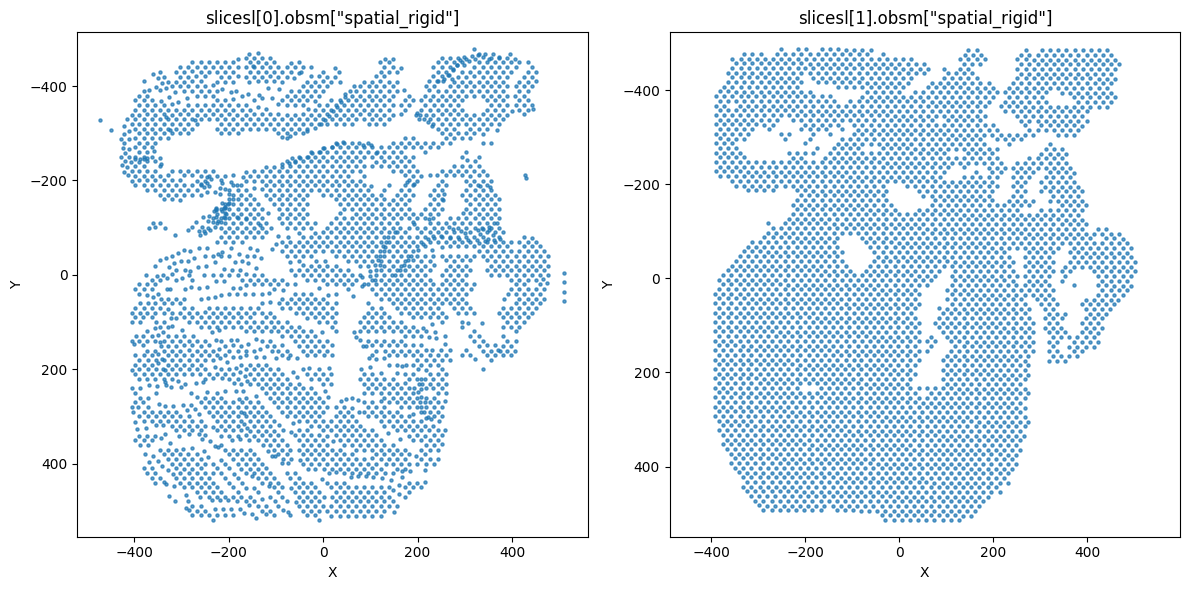

Number of matches (elastic): 1649 / 3184
Match percentage (elastic): 51.79%


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes):
    spatial_elas = slicesl[i].obsm['spatial_rigid']
    ax.scatter(spatial_elas[:, 0], spatial_elas[:, 1], s=5, alpha=0.7)
    ax.set_title(f'slicesl[{i}].obsm["spatial_rigid"]')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axis('equal')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()



cols = [
    'Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage'
]
# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')

# For each query cell, find the nearest ref cell in the reconstructed (elastic) space using 'spatial_elas' coordinates
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the elastic registration coordinates
ref_coords_elas = refAD.obsm['spatial_rigid'][:, :2]
query_coords_elas = queryAD.obsm['spatial_rigid'][:, :2]

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree_elas = cKDTree(ref_coords_elas)
dists_elas, idxs_elas = tree_elas.query(query_coords_elas, k=1)

# Compare cell types
matches_elas = query_celltypes == ref_celltypes[idxs_elas]

# Optionally, print or summarize the results
print(f"Number of matches (elastic): {matches_elas.sum()} / {len(matches_elas)}")
print(f"Match percentage (elastic): {matches_elas.mean()*100:.2f}%")

# Store nearest ref cell type and match result in queryAD.obs
queryAD.obs['NearestRefCellType_elas'] = ref_celltypes[idxs_elas]
queryAD.obs['CellTypeMatch_elas'] = matches_elas




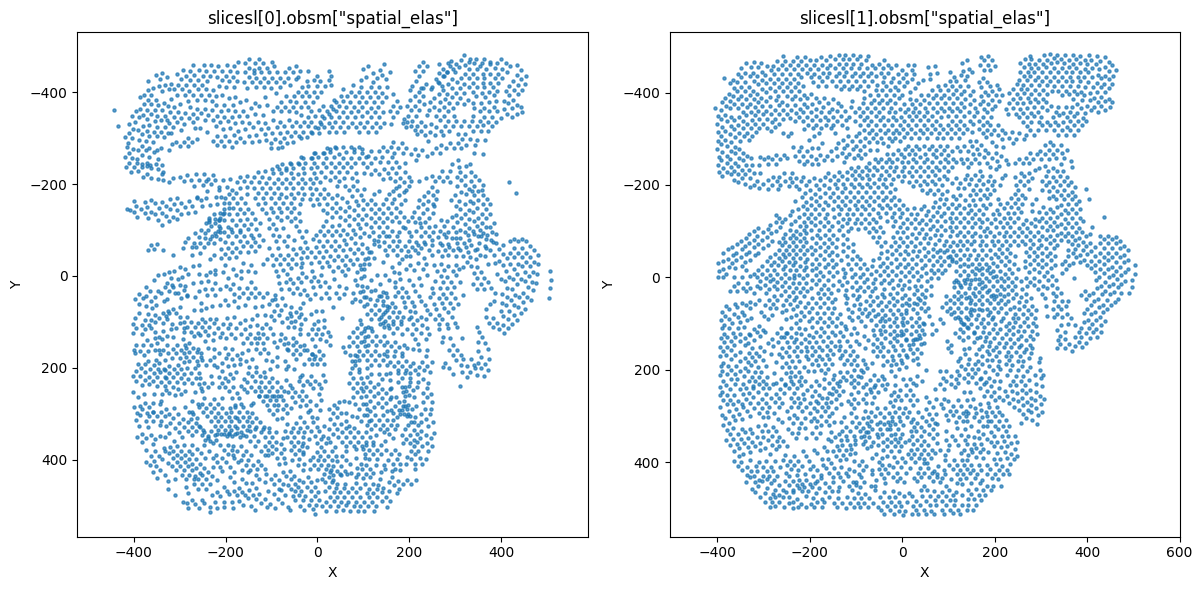

Number of matches (elastic): 1469 / 3184
Match percentage (elastic): 46.14%


In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes):
    spatial_elas = slicesl[i].obsm['spatial_elas']
    ax.scatter(spatial_elas[:, 0], spatial_elas[:, 1], s=5, alpha=0.7)
    ax.set_title(f'slicesl[{i}].obsm["spatial_elas"]')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axis('equal')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()



cols = [
    'Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage'
]
# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')

# For each query cell, find the nearest ref cell in the reconstructed (elastic) space using 'spatial_elas' coordinates
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the elastic registration coordinates
ref_coords_elas = refAD.obsm['spatial_elas'][:, :2]
query_coords_elas = queryAD.obsm['spatial_elas'][:, :2]

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree_elas = cKDTree(ref_coords_elas)
dists_elas, idxs_elas = tree_elas.query(query_coords_elas, k=1)

# Compare cell types
matches_elas = query_celltypes == ref_celltypes[idxs_elas]

# Optionally, print or summarize the results
print(f"Number of matches (elastic): {matches_elas.sum()} / {len(matches_elas)}")
print(f"Match percentage (elastic): {matches_elas.mean()*100:.2f}%")

# Store nearest ref cell type and match result in queryAD.obs
queryAD.obs['NearestRefCellType_elas'] = ref_celltypes[idxs_elas]
queryAD.obs['CellTypeMatch_elas'] = matches_elas




In [27]:
queryAD.obsm['X_STGEARS_spatial'] = queryAD.obsm['spatial_elas'][:,:2].copy()

In [32]:
queryAD.write_h5ad('query_STGEARS.h5ad')

In [26]:
refAD.obsm['X_STGEARS_spatial'] = refAD.obsm['spatial_elas'][:,:2].copy()
refAD.write_h5ad('ref_STGEARS.h5ad')

In [28]:
queryAD.obsm['spatial_elas'][:,:2]

array([[ 229.47903813, -466.14793937],
       [ 263.63135795, -461.17834073],
       [ 283.62238608, -463.73889991],
       ...,
       [  88.20011034,  511.20981614],
       [ 100.79834118,  511.3727785 ],
       [ 122.95401364,  511.03646835]])

In [22]:
refAD.obsm['spatial_elas']

array([[-257.90049778, -477.90868297,    1.        ],
       [-226.93045547, -477.87506423,    1.        ],
       [-210.1529812 , -477.80877366,    1.        ],
       ...,
       [  91.06312806,  512.38934259,    1.        ],
       [ 110.27476114,  509.90530061,    1.        ],
       [ 125.31431915,  512.40216502,    1.        ]])

In [15]:
queryAD.obsm['X_STGEARS_spatial']

array([[ 229.47903813, -466.14793937,    0.        ],
       [ 263.63135795, -461.17834073,    0.        ],
       [ 283.62238608, -463.73889991,    0.        ],
       ...,
       [  88.20011034,  511.20981614,    0.        ],
       [ 100.79834118,  511.3727785 ,    0.        ],
       [ 122.95401364,  511.03646835,    0.        ]])

In [13]:
queryAD.write_h5ad('query_STGEARS.h5ad')